In [27]:
import numpy as np
import pandas as pd
import random

from bingo.evolutionary_algorithms.generalized_crowding import GeneralizedCrowdingEA
from bingo.evolutionary_optimizers.serial_archipelago import SerialArchipelago
from bingo . evolutionary_algorithms . age_fitness import AgeFitnessEA # evolutionary algorithm
from bingo . evolutionary_optimizers . island import Island 
from bingo.symbolic_regression.symbolic_regressor import SymbolicRegressor
from bingo.symbolic_regression import ComponentGenerator , AGraphGenerator #generadores
from bingo.symbolic_regression import AGraphCrossover, AGraphMutation    #Cruza y mutación
from bingo.symbolic_regression.agraph.agraph import AGraph
from bingo.symbolic_regression.explicit_regression import ExplicitRegression , ExplicitTrainingData
from bingo.evaluation.fitness_function import VectorBasedFunction
from bingo.evaluation.evaluation import Evaluation
from bingo.local_optimizers.scipy_optimizer import ScipyOptimizer
import matplotlib.pyplot as plt
import math
import sympy as sp
#fitness function
from bingo.local_optimizers.local_opt_fitness import LocalOptFitnessFunction # CLO
from functools import lru_cache
from sympy.parsing.sympy_parser import (parse_expr, standard_transformations,
                                        implicit_multiplication_application, convert_xor)

In [ ]:
"""
CODIGO OFICIAL DE BINGO

import numpy as np # for generating data
from bingo . evolutionary_algorithms . age_fitness import AgeFitnessEA # evolutionary algorithm
from bingo . evolutionary_optimizers . island import Island # evolutionary optimizer
# components for evaluation
from bingo . evaluation . evaluation import Evaluation
from bingo . symbolic_regression import ExplicitRegression , ExplicitTrainingData 
#fitness function
from bingo . local_optimizers . continuous_local_opt import ContinuousLocalOptimization # CLO
# generators
from bingo . symbolic_regression import ComponentGenerator , AGraphGenerator
# crossover and mutation
from bingo . symbolic_regression import AGraphCrossover, AGraphMutation

# hyperparams
POP_SIZE = 100
STACK_SIZE = 20

# make some data
x = np . linspace ( -10 , 10 , 100) . reshape ([ -1 , 1])
y = x **2 + 3.5* x **3
training_data = ExplicitTrainingData (x , y )

# setup generator to generate equations using variables , constants , + , -, and *
component_generator = ComponentGenerator ( x . shape [1])
component_generator . add_operator (" + ")
component_generator . add_operator (" -")
component_generator . add_operator (" * ")

# agraphs of equations will have STACK_SIZE (20) commands and will use algebraic simplification
agraph_generator = AGraphGenerator ( STACK_SIZE , component_generator , use_simplification = True )

# crossover and mutation
crossover = AGraphCrossover ()
mutation = AGraphMutation ( component_generator )

# defining evaluation
fitness = ExplicitRegression ( training_data =
training_data , metric =" mse ")
local_opt_fitness = ContinuousLocalOptimization (
fitness , algorithm =" lm ")
evaluator = Evaluation ( local_opt_fitness )

# setup evolutionary algorithm
ea = AgeFitnessEA ( evaluator , agraph_generator ,
crossover , mutation , 0.4 , 0.4 , POP_SIZE )

# setup evolutionary optimizer
island = Island ( ea , agraph_generator , POP_SIZE )

# run !
opt_result = island . evolve_until_convergence (
max_generations =500 , fitness_threshold =1.0 e -4)

# print best individual from last generation
print ( opt_result . get_best_individual () )
"""

In [ ]:
P = 150
Complejidad = 10

## Primera Ecuación (para agarrar confianza)

$\frac{d y}{dx} - y = 0 \ , \quad y(0) = 1$

$y(x) = e^{x}$

## 1) Iniciar Población

In [ ]:
"""
component_generator = ComponentGenerator(1) #el 1 es la dimensión de X
component_generator.add_operator ("+")
component_generator.add_operator ("-")
component_generator.add_operator ("*")
component_generator.add_operator ("/")
component_generator.add_operator ("pow")
component_generator.add_operator ("exp")
component_generator.add_operator ("sin")
component_generator.add_operator ("cos")

agraph_generator = AGraphGenerator(Complejidad ,component_generator , use_simplification = True)
"""

In [ ]:
"""
#CADA VEZ QUE SE COMPILA ESTE BLOQUE SE HACE OTRA POBLACIÓN, CUIDADO
poblacion = []
for i in range(P):
    cromosoma = agraph_generator()
    poblacion.append(cromosoma)

print(poblacion[0].get_formatted_string("console"), "\n")
print(poblacion[1].get_formatted_string("console"), "\n")
print(poblacion[2].get_formatted_string("console"), "\n")
print(poblacion[3].get_formatted_string("console"), "\n")
print(poblacion[4].get_formatted_string("console"), "\n")
print(len(poblacion))
"""

1 

1 + exp(1) 

1.000000 

(1.000000)((X_0)^(-1)) 

1.000000 

150


In [ ]:
"""
print(poblacion[0].get_formatted_string("console"), "\n")
"""

((X_0)^(-1))((cos(cos(X_0)) - (X_0))^((-1)(cos(cos(X_0)) - (X_0)))) - (X_0) 



### Al final me di cuenta que toda la sección de iniciar población no sirve de nada para el AG, pero me ayudó mucho a entender que estaba pasando, asi que lo voy a dejar tal cual

## 2) Evaluación de individuos

In [ ]:

def Make_Xi(seed: int, n_points: int, min = float, max = float):
    rng = np.random.default_rng(seed)
    nosequenombreponerperoesunarray = np.sort(rng.uniform(min, max, size=n_points))
    return nosequenombreponerperoesunarray.reshape(-1, 1)
Xi = Make_Xi(67, 100, 0.01, 0.99)
print(Xi.shape)


(100, 1)


In [ ]:
"""
class EDO1(VectorBasedFunction):
    def __init__(self, x, lambdA ):
        super().__init__(metric="mse")
        self.x = x
        self.lambdA = lambdA


    def evaluate_fitness_vector(self, individual):
        y, dy_dx = individual.evaluate_equation_with_x_gradient_at(self.x)

        y = y[:, 0]
        dy_dx = dy_dx[:, 0]


        #DEBE CUMPLIR LA EDO
        residual1 = dy_dx - y


        #DEBE CUMPLIR LA CONDICIÓN INICIAL  y(0) = 1
        ConIni = individual.evaluate_equation_at(np.array([[0.0]]))[0, 0]

        residual2 = np.array([ConIni - 1.0])

        return np.concatenate([residual1, self.lambdA * residual2
        ])
"""

In [ ]:
"""
fitness = EDO1(Xi,1) # Función objetivo
optimizer = ScipyOptimizer(fitness, method="lm",param_init_bounds=[-1, 1])
local_opt_fitness = LocalOptFitnessFunction(fitness, optimizer) #Evaluador con optimización local
evaluator = Evaluation(local_opt_fitness)
"""

## Crossover y mutación

In [ ]:
"""
crossover = AGraphCrossover()
mutation = AGraphMutation(component_generator)
"""

## Algoritmo

In [ ]:
"""
ea = AgeFitnessEA (evaluator , agraph_generator ,crossover , mutation , 0.5 , 0.5 , P)
island = Island(ea , agraph_generator , P)
"""

In [ ]:
"""
opt_result = island.evolve_until_convergence(max_generations = 100 , fitness_threshold = 1e-10)

print(island.get_best_individual())
"""

exp(X_0)


## Ecuación 2

$\frac{\partial^{4} u(x)}{\partial x^{4}}  - \frac{w(x)}{El} = 0$

$u(0)=0,\ \ \  u(l)=0,  \ \ \  \frac{d^{2} u}{dx^{2}} - k =0, \ \ \ k(0)=0, \ \ \ k(l)=0$

In [48]:

x_sym = sp.Symbol('X_0')
transformaciones = standard_transformations + (implicit_multiplication_application, convert_xor)

import re
MARCA = 1_000_000

@lru_cache(maxsize=None)
def _simbolicas(estructura, k):
    # las constantes marcadas (1000000.000000, 1000001.000000...) se vuelven C_0, C_1...
    s = re.sub(r'\d+\.\d{6}', lambda m: f"C_{int(float(m.group())) - MARCA}", estructura)
    cs = [sp.Symbol(f"C_{i}") for i in range(k)]
    loc = {'X_0': x_sym, **{f"C_{i}": cs[i] for i in range(k)}}
    expr = parse_expr(s, local_dict=loc, transformations=transformaciones)
    return [sp.lambdify([x_sym, *cs], sp.diff(expr, x_sym, n) if n else expr, 'numpy')
            for n in (0, 2, 4)]

def derivadas_sympy(individual):
    k = individual.get_number_local_optimization_params()
    consts = [float(np.asarray(c).ravel()[0]) for c in individual.constants]
    marcado = individual.copy()
    marcado.set_local_optimization_params([MARCA + i for i in range(k)])
    f0, f2, f4 = _simbolicas(marcado.get_formatted_string("sympy"), k)
    return (lambda p: f0(p, *consts), lambda p: f2(p, *consts), lambda p: f4(p, *consts))

def evalua(f, pts):
    # si la expresión es constante, lambdify regresa un escalar: lo estiramos al tamaño de pts
    return np.broadcast_to(np.asarray(f(pts), dtype=float), pts.shape)  

In [56]:
class EDO2(VectorBasedFunction):

    def __init__(self, n_datos=2, lambdA=1):
        super().__init__(metric="mse")

        self.c = 5e-5
        self.l = 10.0
        self.lambdA = lambdA

        # Datos de entrenamiento
        self.x_data = np.linspace(0, self.l, n_datos)

        x = self.x_data

        self.y_data = (
            self.c / 24
            * (x**4 - 2*self.l*x**3 + self.l**3*x)
        )

        # Nueve puntos para evaluar u''''
        self.x_fis = np.arange(1.0, 10.0)

        # Dos puntos para evaluar u''
        self.extremos = np.array([0.0, self.l])

        self.n_res = n_datos + 11

    def evaluate_fitness_vector(self, individual):

        try:
            u, d2u, d4u = derivadas_sympy(individual)

            # Error respecto a los datos conocidos
            residual_datos = (
                evalua(u, self.x_data) - self.y_data
            )

            # Ecuación diferencial: u'''' = c
            residual_edo = (
                evalua(d4u, self.x_fis) - self.c
            )

            # Condiciones de frontera: u''(0)=u''(10)=0
            residual_frontera = evalua(
                d2u, self.extremos
            )

            residuos = np.concatenate([
                residual_datos,
                self.lambdA * residual_edo,
                self.lambdA * residual_frontera
            ])

            if not np.all(np.isfinite(residuos)):
                return np.full(self.n_res, 1e10)

            return residuos

        except Exception:
            return np.full(self.n_res, 1e10)

In [50]:
component_generator = ComponentGenerator(1)
component_generator.add_operator("+")
component_generator.add_operator("-")
component_generator.add_operator("*")
agraph_generator = AGraphGenerator(Complejidad, component_generator, use_simplification = True)

Xi = Make_Xi(67, 11, 0.0, 10.0)

fitness = EDO2(Xi, 1)
optimizer = ScipyOptimizer(fitness, method="lm",param_init_bounds=[-1, 1])
local_opt_fitness = LocalOptFitnessFunction(fitness, optimizer)
evaluator = Evaluation(local_opt_fitness)

crossover = AGraphCrossover()
mutation = AGraphMutation(component_generator)

ea = AgeFitnessEA(evaluator, agraph_generator, crossover, mutation, 0.5, 0.5, P)
island = Island(ea, agraph_generator, P)

In [51]:
import collections

In [52]:
errores = collections.Counter()
for _ in range(P):
    ind = agraph_generator()
    try:
        u, d2, d4 = derivadas_sympy(ind)
        evalua(d4, Xi[:, 0]); evalua(d2, np.array([0.0, 10.0]))
    except Exception as e:
        errores[type(e).__name__ + ": " + str(e)[:70]] += 1
print("Fallos de", P, ":", dict(errores))

Fallos de 150 : {}


In [53]:
import time
t0 = time.time()
for paso in range(1, 21):
    island.evolve(10)
    print(f"gen {paso*10} | mejor fitness {island.get_best_fitness():.6g} | {time.time()-t0:.0f} s", flush=True)
    if island.get_best_fitness() <= 1e-15: break

gen 10 | mejor fitness 0.139086 | 1 s
gen 20 | mejor fitness 0.139086 | 2 s
gen 30 | mejor fitness 0.0966784 | 4 s
gen 40 | mejor fitness 0.0966784 | 6 s
gen 50 | mejor fitness 0.0966784 | 7 s
gen 60 | mejor fitness 0.012559 | 8 s
gen 70 | mejor fitness 0.012559 | 9 s
gen 80 | mejor fitness 0.0101481 | 10 s
gen 90 | mejor fitness 0.0101481 | 12 s
gen 100 | mejor fitness 0.00937032 | 14 s
gen 110 | mejor fitness 0.00937032 | 17 s
gen 120 | mejor fitness 0.00394025 | 20 s
gen 130 | mejor fitness 0.00394025 | 24 s
gen 140 | mejor fitness 0.00393556 | 28 s
gen 150 | mejor fitness 0.00393556 | 35 s
gen 160 | mejor fitness 0.00393556 | 42 s
gen 170 | mejor fitness 0.00393556 | 47 s
gen 180 | mejor fitness 0.00393556 | 52 s
gen 190 | mejor fitness 0.00393556 | 60 s
gen 200 | mejor fitness 0.00393556 | 65 s


In [ ]:
ea = GeneralizedCrowdingEA(evaluator, crossover, mutation, 0.5, 0.5)
island = Island(ea, agraph_generator, P)
archipielago = SerialArchipelago(island, num_islands=10)

t0 = time.time()
for paso in range(1, 31):
    archipielago.evolve(10)
    print(f"gen {paso*10} | mejor fitness {archipielago.get_best_fitness():.6g} | {time.time()-t0:.0f} s", flush=True)
    if archipielago.get_best_fitness() <= 1e-15: break
mejor = archipielago.get_best_individual()

gen 10 | mejor fitness 0.11664 | 8 s
gen 20 | mejor fitness 0.11664 | 15 s
gen 30 | mejor fitness 0.11664 | 21 s
gen 40 | mejor fitness 0.0520481 | 27 s
gen 50 | mejor fitness 0.0520481 | 33 s
gen 60 | mejor fitness 0.0145851 | 40 s
gen 70 | mejor fitness 0.012556 | 47 s
gen 80 | mejor fitness 0.012556 | 54 s
gen 90 | mejor fitness 0.012556 | 61 s
gen 100 | mejor fitness 0.012556 | 68 s
gen 110 | mejor fitness 0.012556 | 76 s
gen 120 | mejor fitness 0.012556 | 84 s
gen 130 | mejor fitness 0.00942653 | 90 s
gen 140 | mejor fitness 0.00168634 | 98 s
gen 150 | mejor fitness 0.00168634 | 105 s
gen 160 | mejor fitness 0.00168634 | 116 s
gen 170 | mejor fitness 0.00168634 | 124 s
gen 180 | mejor fitness 0.00168634 | 132 s
gen 190 | mejor fitness 0.00168634 | 141 s
gen 200 | mejor fitness 0.00168634 | 150 s
gen 210 | mejor fitness 0.00168634 | 159 s
gen 220 | mejor fitness 0.00168634 | 168 s
gen 230 | mejor fitness 0.00168634 | 177 s
gen 240 | mejor fitness 0.000855432 | 186 s
gen 250 | mejor

fitness: 0.0008554319938489655
Obtenida: 2.08155268213088e-6*X_0**4 - 4.1345943948938e-5*X_0**3 + 0.010265200284679
Paper:    2.08333333333333e-6*X_0**4 - 4.16666666666667e-5*X_0**3 + 0.00208333333333333*X_0


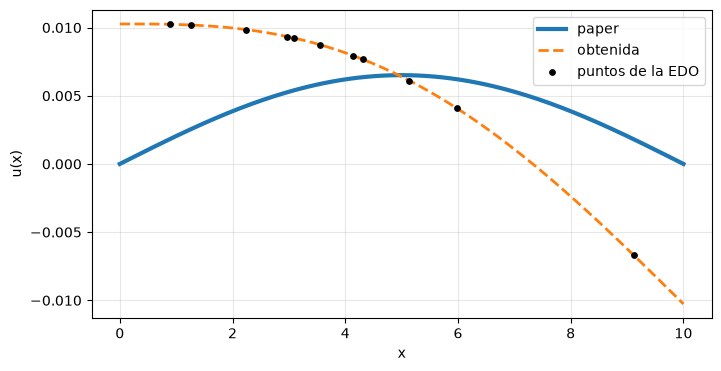

In [54]:
mejor = archipielago.get_best_individual()
print("fitness:", archipielago.get_best_fitness())

# fórmula expandida con las constantes EXACTAS (el print de bingo solo muestra 6 decimales)
def expresion_exacta(ind):
    k = ind.get_number_local_optimization_params()
    consts = [float(np.asarray(c).ravel()[0]) for c in ind.constants]
    marcado = ind.copy()
    marcado.set_local_optimization_params([MARCA + i for i in range(k)])
    s = re.sub(r'\d+\.\d{6}', lambda m: f"C_{int(float(m.group())) - MARCA}",
               marcado.get_formatted_string("sympy"))
    cs = [sp.Symbol(f"C_{i}") for i in range(k)]
    loc = {'X_0': x_sym, **{f"C_{i}": cs[i] for i in range(k)}}
    expr = parse_expr(s, local_dict=loc, transformations=transformaciones)
    return sp.expand(expr.subs({cs[i]: consts[i] for i in range(k)}))

c, l = 5e-5, 10
u_mia = expresion_exacta(mejor)
u_paper = sp.expand(sp.Rational(1, 24) * c * (x_sym**4 - 2*l*x_sym**3 + l**3*x_sym))
print("Obtenida:", u_mia)
print("Paper:   ", u_paper)


# gráfica
f_mia = sp.lambdify(x_sym, u_mia, 'numpy')
f_pap = sp.lambdify(x_sym, u_paper, 'numpy')
xs = np.linspace(0, l, 200)

plt.figure(figsize=(8, 4))
plt.plot(xs, evalua(f_pap, xs), lw=3, label="paper")
plt.plot(xs, evalua(f_mia, xs), '--', lw=2, label="obtenida")
plt.scatter(Xi[:, 0], evalua(f_mia, Xi[:, 0]), s=15, c='k', zorder=3, label="puntos de la EDO")
plt.xlabel("x"); plt.ylabel("u(x)"); plt.grid(alpha=0.3); plt.legend()
plt.show()

## Ecuacion 3

$\nabla ^{2} u(x)= f(x)$

In [21]:
@lru_cache(maxsize=None)
def _simbolicas_poisson(estructura, k, d):
    def a_simbolo(m):
        v = float(m.group())
        return f"C_{int(round(v)) - MARCA}" if v >= MARCA else m.group()
    s = re.sub(r'\d+\.\d+', a_simbolo, estructura)
    xs = [sp.Symbol(f"X_{i}") for i in range(d)]
    cs = [sp.Symbol(f"C_{i}") for i in range(k)]
    loc = {**{f"X_{i}": xs[i] for i in range(d)}, **{f"C_{i}": cs[i] for i in range(k)}}
    expr = parse_expr(s, local_dict=loc, transformations=transformaciones)
    laplaciano = sum(sp.diff(expr, xi, 2) for xi in xs)
    return (sp.lambdify([*xs, *cs], expr, 'numpy'),
            sp.lambdify([*xs, *cs], laplaciano, 'numpy'))

def derivadas_poisson(individual, d):
    k = individual.get_number_local_optimization_params()
    consts = [float(np.asarray(c).ravel()[0]) for c in individual.constants]
    marcado = individual.copy()
    marcado.set_local_optimization_params([float(MARCA + i) for i in range(k)])
    u, laplaciano = _simbolicas_poisson(marcado.get_formatted_string("sympy"), k, d)
    return u, laplaciano, consts

def evalua_nd(f, pts, consts):
    return np.broadcast_to(np.asarray(f(*pts.T, *consts), dtype=float), (pts.shape[0],))

In [22]:
def Make_Puntos(seed, d, n_borde, m_interior):
    rng = np.random.default_rng(seed)
    interior = rng.uniform(0.0, 1.0, size=(m_interior, d))
    if d == 1:
        borde = np.array([[0.0], [1.0]])
    else:
        borde = rng.uniform(0.0, 1.0, size=(n_borde, d))
        cara = rng.integers(0, d, size=n_borde)                 # en qué coordenada cae la frontera
        borde[np.arange(n_borde), cara] = rng.integers(0, 2, size=n_borde)   # en 0 o en 1
    return interior, borde

In [23]:
class EDO3(VectorBasedFunction):
    def __init__(self, interior, borde, lambdA ):
        super().__init__(metric="mse")
        self.interior = interior
        self.borde = borde
        self.lambdA = lambdA
        self.d = interior.shape[1]
        self.n_res = len(interior) + len(borde)


    def evaluate_fitness_vector(self, individual):
        try:
            u, laplaciano, consts = derivadas_poisson(individual, self.d)

            X = self.interior
            f = -self.d * np.pi**2 * np.prod(np.sin(np.pi * X), axis=1)

            #DEBE CUMPLIR LA EDO   laplaciano(u) = f
            residual1 = evalua_nd(laplaciano, X, consts) - f

            #DEBE CUMPLIR LA FRONTERA   u = 0
            residual2 = evalua_nd(u, self.borde, consts)

            RESIDUALULTRAMASTERpro = np.concatenate([residual1, self.lambdA * residual2])

            if not np.all(np.isfinite(RESIDUALULTRAMASTERpro)):
                return np.full(self.n_res, 1e10)
            return RESIDUALULTRAMASTERpro

        except Exception:
            return np.full(self.n_res, 1e10)

In [24]:
d = 1
n_borde, m_interior = 2, 20        # para 2D, como el paper: n_borde = 16, m_interior = 32

component_generator = ComponentGenerator(d)
component_generator.add_operator("*")
component_generator.add_operator("sin")
agraph_generator = AGraphGenerator(20, component_generator, use_simplification = True)   # complejidad 20, Tabla 2 del paper

interior, borde = Make_Puntos(3, d, n_borde, m_interior)

fitness = EDO3(interior, borde, 1)
optimizer = ScipyOptimizer(fitness, method="lm")
local_opt_fitness = LocalOptFitnessFunction(fitness, optimizer)
evaluator = Evaluation(local_opt_fitness)

crossover = AGraphCrossover()
mutation = AGraphMutation(component_generator)

ea = AgeFitnessEA(evaluator, agraph_generator, crossover, mutation, 0.5, 0.5, P)
island = Island(ea, agraph_generator, P)

In [25]:
t0 = time.time()
for paso in range(1, 31):
    island.evolve(10)
    print(f"gen {paso*10} | mejor fitness {island.get_best_fitness():.6g} | {time.time()-t0:.0f} s", flush=True)
    if island.get_best_fitness() <= 1e-15: break
mejor = island.get_best_individual()
print(mejor.get_formatted_string("console"))

gen 10 | mejor fitness 0.577957 | 4 s
gen 20 | mejor fitness 0.577957 | 8 s
gen 30 | mejor fitness 0.577957 | 11 s
gen 40 | mejor fitness 0.577957 | 15 s
gen 50 | mejor fitness 0.577957 | 18 s
gen 60 | mejor fitness 0.577957 | 21 s
gen 70 | mejor fitness 0.577957 | 23 s
gen 80 | mejor fitness 0.577957 | 25 s
gen 90 | mejor fitness 0.544382 | 27 s
gen 100 | mejor fitness 0.544382 | 30 s
gen 110 | mejor fitness 0.544382 | 36 s
gen 120 | mejor fitness 0.544382 | 40 s
gen 130 | mejor fitness 0.544382 | 45 s
gen 140 | mejor fitness 0.544382 | 49 s
gen 150 | mejor fitness 0.516609 | 55 s
gen 160 | mejor fitness 0.516609 | 59 s
gen 170 | mejor fitness 0.516609 | 62 s
gen 180 | mejor fitness 0.516609 | 67 s
gen 190 | mejor fitness 0.516609 | 72 s
gen 200 | mejor fitness 0.443789 | 78 s
gen 210 | mejor fitness 0.443789 | 84 s
gen 220 | mejor fitness 0.443789 | 91 s
gen 230 | mejor fitness 0.443387 | 98 s
gen 240 | mejor fitness 0.443387 | 104 s
gen 250 | mejor fitness 0.443387 | 112 s
gen 260 |

In [26]:
Xt = np.random.default_rng(0).uniform(0, 1, size=(1000, d))
u_obt = mejor.evaluate_equation_at(Xt)[:, 0]
u_paper = np.prod(np.sin(np.pi * Xt), axis=1)
print("error máximo vs. solución del paper:", np.max(np.abs(u_obt - u_paper)))
print("constantes:", [float(np.asarray(c).ravel()[0]) for c in mejor.constants], "| pi =", np.pi)

error máximo vs. solución del paper: 3.1054654644349706
constantes: [-12.186213099136758, 360.58232436276165] | pi = 3.141592653589793


In [28]:
N_CORRIDAS = 30
MAX_GENERACIONES = 1000
UMBRAL = 1e-15

def experimento_poisson(d=1):

    configuraciones = {
        1: (2, 2),
        2: (16, 32),
        3: (20, 64)
    }

    n_borde, m_interior = configuraciones[d]

    # Mismos puntos para todas las corridas de esta configuración
    interior, borde = Make_Puntos(
        3, d, n_borde, m_interior
    )

    # Conjunto independiente para evaluar generalización
    Xt = np.random.default_rng(2026).uniform(
        0, 1, size=(1000, d)
    )

    y_real = np.prod(np.sin(np.pi * Xt), axis=1)

    resultados = []

    for corrida in range(N_CORRIDAS):

        seed = 1000 + corrida

        random.seed(seed)
        np.random.seed(seed)

        # Construir nuevamente todos los componentes
        componentes = ComponentGenerator(d)
        componentes.add_operator("*")
        componentes.add_operator("sin")

        generador = AGraphGenerator(
            20, componentes,
            use_simplification=True
        )

        fitness = EDO3(interior, borde, 1)

        optimizer = ScipyOptimizer(
            fitness,
            method="lm",
            param_init_bounds=[-1, 1]
        )

        evaluador = Evaluation(
            LocalOptFitnessFunction(fitness, optimizer)
        )

        crossover = AGraphCrossover()
        mutation = AGraphMutation(componentes)

        ea = GeneralizedCrowdingEA(
            evaluador,
            crossover,
            mutation,
            0.5,
            0.5
        )

        isla = Island(ea, generador, 150)

        archipielago = SerialArchipelago(
            isla,
            num_islands=10
        )

        inicio = time.perf_counter()
        convergio = False
        generacion = 0

        for generacion in range(1, MAX_GENERACIONES + 1):

            archipielago.evolve(1)

            if archipielago.get_best_fitness() <= UMBRAL:
                convergio = True
                break

        mejor = archipielago.get_best_individual()
        fitness_final = archipielago.get_best_fitness()

        try:
            y_pred = mejor.evaluate_equation_at(Xt)[:, 0]

            if not np.all(np.isfinite(y_pred)):
                raise ValueError("Predicción no finita")

            mse_test = np.mean((y_pred - y_real)**2)
            error_max = np.max(np.abs(y_pred - y_real))

        except Exception:
            mse_test = np.inf
            error_max = np.inf

        resultados.append({
            "corrida": corrida + 1,
            "seed": seed,
            "fitness_final": fitness_final,
            "mse_test": mse_test,
            "error_maximo": error_max,
            "generaciones": generacion,
            "convergio": convergio,
            "tiempo_segundos": time.perf_counter() - inicio,
            "expresion": mejor.get_formatted_string("sympy")
        })

        print(
            f"Corrida {corrida+1}/{N_CORRIDAS} | "
            f"Fitness: {fitness_final:.3e} | "
            f"Generaciones: {generacion} | "
            f"Convergió: {convergio}"
        )

    return pd.DataFrame(resultados)

In [ ]:
resultados_1d = experimento_poisson(d=1)

Corrida 1/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 2/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 3/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 4/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 5/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 6/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True


c:\Users\DIEGO\IDM\5to semestre\bioinspirados\SP\AlgoritmoGeneticoED\.venv\Lib\site-packages\scipy\optimize\_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


Corrida 7/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 8/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 9/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 10/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 11/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 12/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 13/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 14/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 15/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 16/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 17/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 18/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 19/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 20/30 | Fitness: 3.749e-33 | Generaciones: 1 | Convergió: True
Corrida 2

In [61]:
resultados_1d.to_csv(
    "resultados_poisson_1d.csv",
    index=False
)

In [30]:
def resumir_resultados(df):

    columnas = [
        "fitness_final",
        "mse_test",
        "error_maximo",
        "tiempo_segundos"
    ]

    resumen = df[columnas].agg([
        "mean",
        "median",
        "std"
    ])

    print(resumen)

    tasa = df["convergio"].mean() * 100

    print(f"Tasa de convergencia: {tasa:.2f}%")

    return resumen

In [31]:
resumen = resumir_resultados(resultados_1d)

        fitness_final  mse_test  error_maximo  tiempo_segundos
mean     3.749399e-33       0.0           0.0         4.764994
median   3.749399e-33       0.0           0.0         4.604792
std      1.391850e-48       0.0           0.0         0.976377
Tasa de convergencia: 100.00%


In [57]:
N_CORRIDAS = 30
MAX_GENERACIONES = 1000
UMBRAL = 1e-15


def experimento_euler(n_datos=2, prueba=1):

    # Validar configuración
    if n_datos not in [2, 3, 11]:
        raise ValueError("n_datos debe ser 2, 3 u 11")

    operadores = {
        1: ["+", "-", "*"],
        2: ["+", "-", "*", "pow", "sin", "/"]
    }

    if prueba not in operadores:
        raise ValueError("prueba debe ser 1 o 2")

    # Parámetros físicos
    c = 5e-5
    l = 10.0

    # Conjunto independiente de evaluación
    Xt = np.linspace(0, l, 201).reshape(-1, 1)

    x = Xt[:, 0]

    # Solución analítica del artículo
    y_real = (
        c / 24
        * (x**4 - 2*l*x**3 + l**3*x)
    )

    resultados = []

    for corrida in range(N_CORRIDAS):

        seed = 1000 + corrida

        random.seed(seed)
        np.random.seed(seed)

        # Nuevo generador de cromosomas
        componentes = ComponentGenerator(1)

        for operador in operadores[prueba]:
            componentes.add_operator(operador)

        generador = AGraphGenerator(
            10,
            componentes,
            use_simplification=True
        )

        # Función objetivo
        fitness = EDO2(
            n_datos=n_datos,
            lambdA=1
        )

        # Optimización local
        optimizer = ScipyOptimizer(
            fitness,
            method="lm",
            param_init_bounds=[-1, 1]
        )

        evaluador = Evaluation(
            LocalOptFitnessFunction(
                fitness,
                optimizer
            )
        )

        # Operadores genéticos
        crossover = AGraphCrossover()
        mutation = AGraphMutation(componentes)

        # Deterministic Crowding
        ea = GeneralizedCrowdingEA(
            evaluador,
            crossover,
            mutation,
            0.5,
            0.5
        )

        # Nueva población
        isla = Island(
            ea,
            generador,
            150
        )

        # Archipiélago de 10 islas
        archipielago = SerialArchipelago(
            isla,
            num_islands=10
        )

        inicio = time.perf_counter()

        convergio = False
        generacion = 0

        # Evolución
        for generacion in range(1, MAX_GENERACIONES + 1):

            archipielago.evolve(1)

            fitness_actual = archipielago.get_best_fitness()

            if fitness_actual <= UMBRAL:
                convergio = True
                break

        # Mejor cromosoma
        mejor = archipielago.get_best_individual()

        fitness_final = archipielago.get_best_fitness()

        # Evaluación fuera del entrenamiento
        try:
            y_pred = mejor.evaluate_equation_at(Xt)[:, 0]

            if not np.all(np.isfinite(y_pred)):
                raise ValueError("Predicción no finita")

            mse_test = np.mean(
                (y_pred - y_real)**2
            )

            error_max = np.max(
                np.abs(y_pred - y_real)
            )

        except Exception:
            mse_test = np.inf
            error_max = np.inf

        tiempo = time.perf_counter() - inicio

        # Guardar resultados
        resultados.append({
            "corrida": corrida + 1,
            "seed": seed,
            "n_datos": n_datos,
            "prueba": prueba,
            "fitness_final": fitness_final,
            "mse_test": mse_test,
            "error_maximo": error_max,
            "generaciones": generacion,
            "convergio": convergio,
            "tiempo_segundos": tiempo,
            "expresion": mejor.get_formatted_string("sympy")
        })

        print(
            f"Corrida {corrida+1}/{N_CORRIDAS} | "
            f"Fitness: {fitness_final:.3e} | "
            f"Generaciones: {generacion} | "
            f"Convergió: {convergio} | "
            f"Tiempo: {tiempo:.1f}s"
        )

    return pd.DataFrame(resultados)

In [59]:
resultados_euler_2 = experimento_euler(
    n_datos=2,
    prueba=1
)

Corrida 1/30 | Fitness: 6.459e-31 | Generaciones: 267 | Convergió: True | Tiempo: 93.5s
Corrida 2/30 | Fitness: 0.000e+00 | Generaciones: 495 | Convergió: True | Tiempo: 155.6s
Corrida 3/30 | Fitness: 1.528e-35 | Generaciones: 212 | Convergió: True | Tiempo: 57.4s
Corrida 4/30 | Fitness: 0.000e+00 | Generaciones: 722 | Convergió: True | Tiempo: 527.7s
Corrida 5/30 | Fitness: 3.820e-35 | Generaciones: 522 | Convergió: True | Tiempo: 430.4s
Corrida 6/30 | Fitness: 0.000e+00 | Generaciones: 362 | Convergió: True | Tiempo: 261.4s
Corrida 7/30 | Fitness: 0.000e+00 | Generaciones: 346 | Convergió: True | Tiempo: 260.4s
Corrida 8/30 | Fitness: 5.394e-40 | Generaciones: 451 | Convergió: True | Tiempo: 353.4s
Corrida 9/30 | Fitness: 0.000e+00 | Generaciones: 269 | Convergió: True | Tiempo: 188.9s
Corrida 10/30 | Fitness: 1.272e-40 | Generaciones: 504 | Convergió: True | Tiempo: 408.2s
Corrida 11/30 | Fitness: 2.086e-34 | Generaciones: 396 | Convergió: True | Tiempo: 317.5s
Corrida 12/30 | Fitne

In [60]:
resultados_euler_2.to_csv(
    "euler_2datos_test1.csv",
    index=False
)
resumen = resumir_resultados(resultados_euler_2)

        fitness_final      mse_test  error_maximo  tiempo_segundos
mean     3.014403e-32  2.481699e-31  2.007653e-16       282.874859
median   4.521132e-40  1.809895e-36  4.987330e-18       254.780643
std      1.253921e-31  9.562308e-31  6.763267e-16       179.550509
Tasa de convergencia: 100.00%
